# Cas Kaggle · Cançons de Spotify

**Pregunta:** podem estimar la puntuació de popularitat d’una cançó a partir de les seves característiques?

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit

plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
path = Path('../data/top10s.csv') if Path('../data/top10s.csv').exists() else Path('data/top10s.csv')
dades = pd.read_csv(path, encoding='cp1252').drop(columns=['Unnamed: 0'])
clau_artista = dades['artist'].str.strip().str.casefold()
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
idx_train, idx_test = next(split.split(dades, groups=clau_artista))
train = dades.iloc[idx_train].copy()
test_reservat = dades.iloc[idx_test].copy()
print(f'Cançons: {len(dades)} · Desenvolupament: {len(train)} · Test reservat: {len(test_reservat)}')
print(f'Artistes de desenvolupament: {clau_artista.iloc[idx_train].nunique()} · Artistes de test: {clau_artista.iloc[idx_test].nunique()}')
assert not set(clau_artista.iloc[idx_train]) & set(clau_artista.iloc[idx_test])

Cançons: 603 · Desenvolupament: 471 · Test reservat: 132
Artistes de desenvolupament: 147 · Artistes de test: 37


## 1. Atributs i valors buits

In [ ]:
resum = pd.DataFrame({'tipus':train.dtypes.astype(str), 'valors diferents':train.nunique(), 'buits':train.isna().sum()})
display(resum)
print('Files duplicades completes:', train.duplicated().sum())
print('Parella títol i artista repetida:', train.duplicated(['title','artist']).sum())

,tipus,valors diferents,buits
title,str,454,0
artist,str,147,0
top genre,str,46,0
year,int64,10,0
bpm,int64,96,0
nrgy,int64,74,0
dnce,int64,66,0
dB,int64,13,0
live,int64,58,0
val,int64,92,0


Files duplicades completes: 0
Parella títol i artista repetida: 14


A desenvolupament no hi ha buits ni files idèntiques; 14 files repeteixen una parella títol–artista.

## 2. Popularitat (variable objectiu)

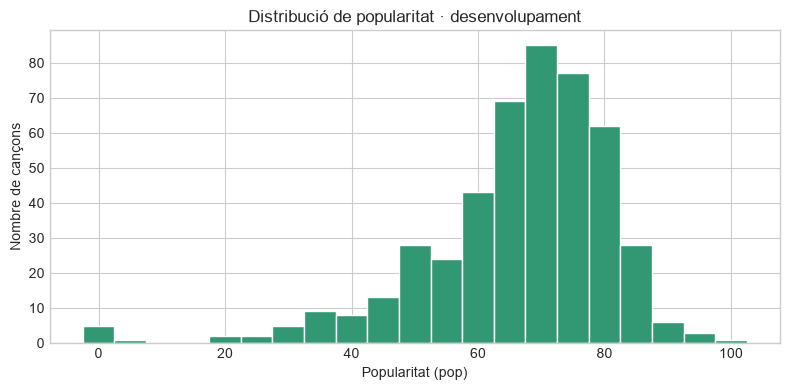

,popularitat
count,471.00
mean,66.42
std,15.05
min,0.00
25%,60.50
50%,69.00
75%,76.00
max,99.00


Valors de popularitat iguals a 0: 5


In [ ]:
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(train['pop'],bins=np.arange(-2.5,105,5),color='#329873',edgecolor='white')
ax.set(title='Distribució de popularitat · desenvolupament',xlabel='Popularitat (pop)',ylabel='Nombre de cançons')
plt.tight_layout();plt.show()
display(train['pop'].describe().round(2).to_frame('popularitat'))
print('Valors de popularitat iguals a 0:', int(train['pop'].eq(0).sum()))

la mediana és 69; hi ha 5 zeros de significat desconegut, que conservem.

## 3. Any i composició de les dades

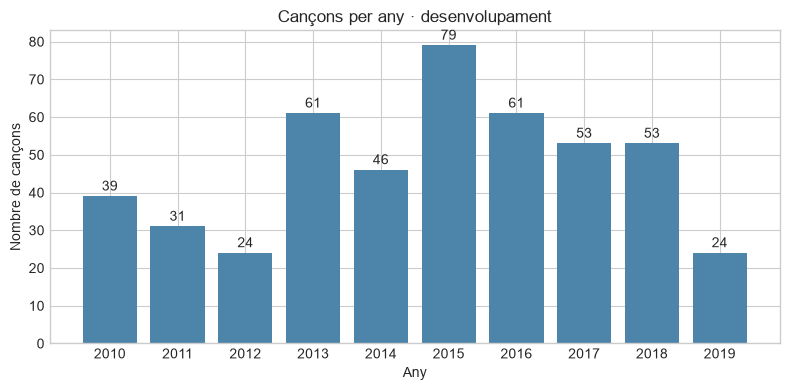

In [ ]:
anys=train.year.value_counts().sort_index()
fig,ax=plt.subplots(figsize=(8,4));bars=ax.bar(anys.index.astype(str),anys.values,color='#4d84aa');ax.bar_label(bars,padding=2)
ax.set(title='Cançons per any · desenvolupament',xlabel='Any',ylabel='Nombre de cançons');plt.tight_layout();plt.show()

els anys estan representats de manera desigual; totes són cançons preseleccionades.

## 4. Correlacions entre atributs

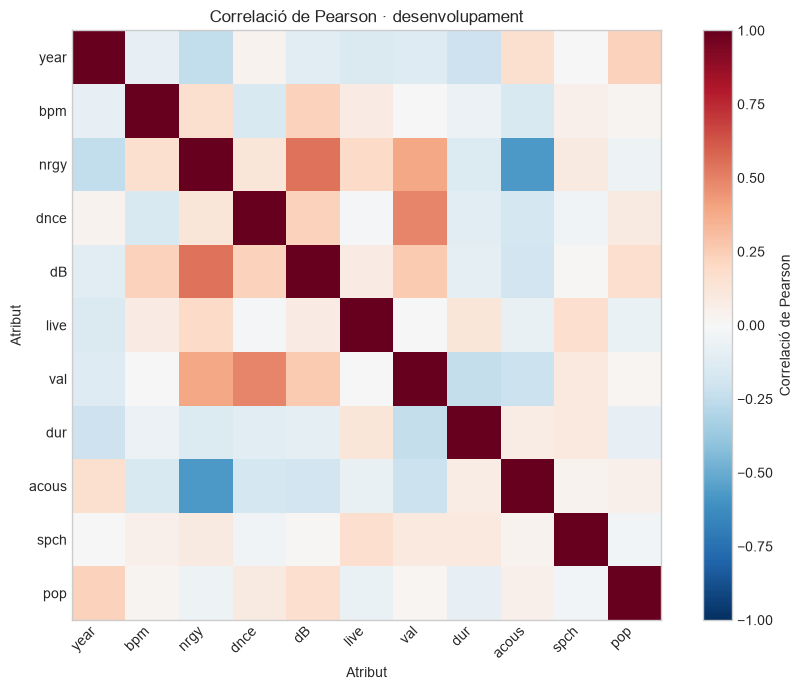

,Pearson amb pop
year,0.233
dB,0.171
dnce,0.088
dur,-0.085
live,-0.065
nrgy,-0.051
acous,0.049
spch,-0.028
bpm,0.027
val,0.018


In [ ]:
numeriques=['year','bpm','nrgy','dnce','dB','live','val','dur','acous','spch','pop']
corr=train[numeriques].corr(method='pearson')
fig,ax=plt.subplots(figsize=(9,7)); im=ax.imshow(corr,cmap='RdBu_r',vmin=-1,vmax=1)
ax.set_xticks(range(len(corr)),corr.columns,rotation=45,ha='right');ax.set_yticks(range(len(corr)),corr.index)
ax.grid(False);ax.set(title='Correlació de Pearson · desenvolupament',xlabel='Atribut',ylabel='Atribut')
fig.colorbar(im,ax=ax,label='Correlació de Pearson');plt.tight_layout();plt.show()
display(corr['pop'].drop('pop').sort_values(key=abs,ascending=False).round(3).to_frame('Pearson amb pop'))

`year` té una correlació de 0,233 amb `pop`; les correlacions musicals són febles.

## 5. Popularitat i característiques musicals

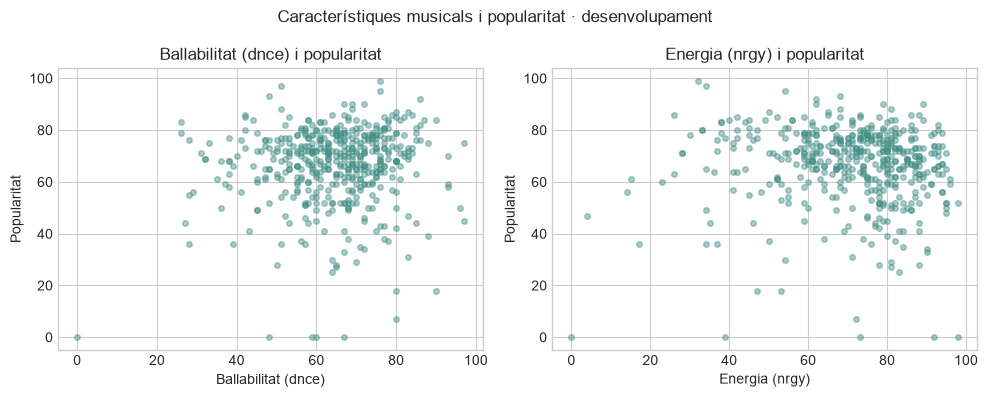

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,col,label in zip(axes,['dnce','nrgy'],['Ballabilitat (dnce)','Energia (nrgy)']):
 ax.scatter(train[col],train['pop'],alpha=.45,s=16,color='#418f86');ax.set(xlabel=label,ylabel='Popularitat',title=label+' i popularitat')
fig.suptitle('Característiques musicals i popularitat · desenvolupament');plt.tight_layout();plt.show()

els núvols mostren com varia la popularitat per a una mateixa característica; no permeten establir causalitat.

## 6. Gèneres i artistes

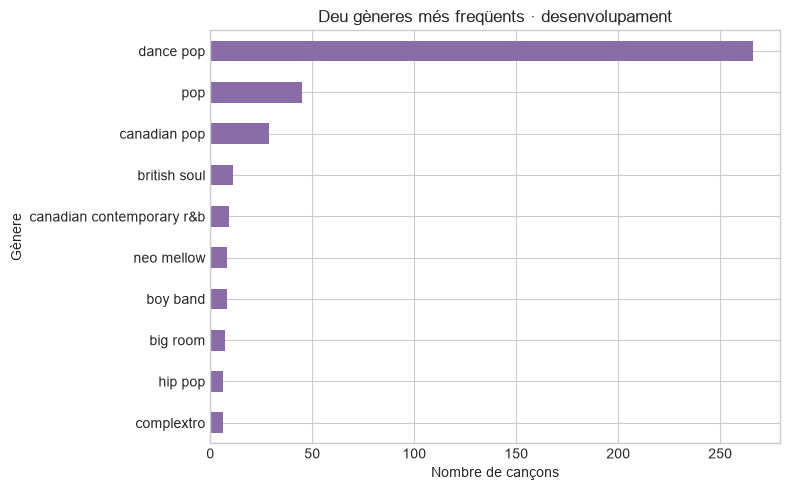

Gèneres diferents: 46
Gèneres amb menys de 5 cançons: 31
Artistes amb més d’una cançó: 90


In [ ]:
generes=train['top genre'].value_counts()
fig,ax=plt.subplots(figsize=(8,5));generes.head(10).sort_values().plot.barh(ax=ax,color='#8a6ca7')
ax.set(title='Deu gèneres més freqüents · desenvolupament',xlabel='Nombre de cançons',ylabel='Gènere');plt.tight_layout();plt.show()
print('Gèneres diferents:', len(generes))
print('Gèneres amb menys de 5 cançons:', int((generes<5).sum()))
print('Artistes amb més d’una cançó:', int((train.artist.str.strip().str.casefold().value_counts()>1).sum()))

`dance pop` domina (266 cançons); 31 dels 46 gèneres tenen menys de 5 exemples.

## 7. Valors extrems

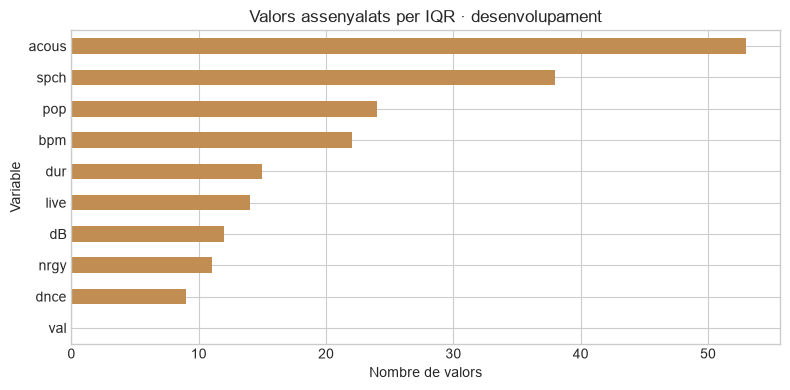

,Nombre
acous,53
spch,38
pop,24
bpm,22
dur,15
live,14
dB,12
nrgy,11
dnce,9
val,0


In [ ]:
variables=['bpm','nrgy','dnce','dB','live','val','dur','acous','spch','pop']
q1=train[variables].quantile(.25);q3=train[variables].quantile(.75);iqr=q3-q1
extrems=((train[variables]<q1-1.5*iqr)|(train[variables]>q3+1.5*iqr)).sum().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(8,4));extrems.sort_values().plot.barh(ax=ax,color='#c18d52')
ax.set(title='Valors assenyalats per IQR · desenvolupament',xlabel='Nombre de valors',ylabel='Variable');plt.tight_layout();plt.show()
display(extrems.to_frame('Nombre'))

IQR assenyala, entre altres, 53 valors d’`acous` i 24 de `pop`. 

## 8. Decisions i límits

- Objectiu: `pop`; mètrica inicial proposada: MAE, en punts de popularitat.
- Descartem l’índex, el títol i l’artista com a predictors inicials.
- Reservem el test per artista; la validació també haurà de respectar els grups.
- No es coneix prou bé quan es va calcular `pop`; no afirmem que es pugui predir un èxit futur.

## 9. Variables per als models

Comencem amb les nou característiques musicals. El títol i l’artista s’exclouen; l’any i el gènere queden pendents de justificar.

In [9]:
predictors = ['bpm', 'nrgy', 'dnce', 'dB', 'live', 'val', 'dur', 'acous', 'spch']
X_train = train[predictors].copy()
y_train = train['pop'].copy()
grups_train = train['artist'].str.strip().str.casefold()
display(X_train.head())

,bpm,nrgy,dnce,dB,live,val,dur,acous,spch
1,87,93,75,-5,52,64,263,24,23
2,120,84,76,-3,29,71,200,10,14
3,119,92,70,-4,8,71,295,0,4
5,65,86,73,-5,11,54,214,4,14
6,120,78,75,-4,4,82,203,0,9


## 10. Baseline

Prediem sempre la mediana del fold d’entrenament i mesurem el MAE amb validació per artistes.

,Fold,Cançons validació,Mediana train,MAE
0,1,95,70.0,11.27
1,2,94,69.0,10.90
2,3,94,69.0,10.17
3,4,94,70.0,10.45
4,5,94,69.0,10.91


MAE mitjà: 10.74 ± 0.39 punts


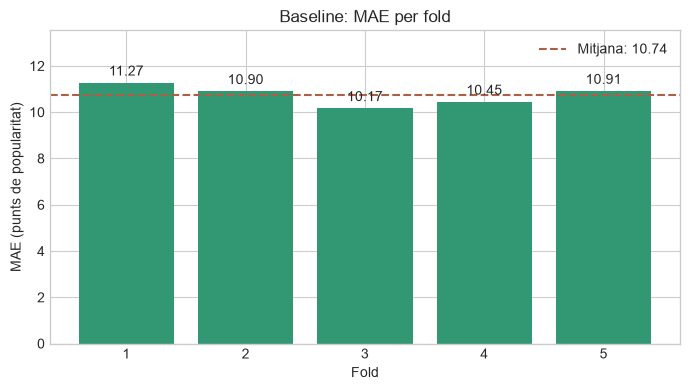

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline

cv = GroupKFold(n_splits=5)
resultats = []
for fold, (idx_fit, idx_val) in enumerate(cv.split(X_train, y_train, groups=grups_train), start=1):
    baseline = make_pipeline(DummyRegressor(strategy='median'))
    baseline.fit(X_train.iloc[idx_fit], y_train.iloc[idx_fit])
    pred = baseline.predict(X_train.iloc[idx_val])
    resultats.append({
        'Fold': fold,
        'Cançons validació': len(idx_val),
        'Mediana train': baseline.named_steps['dummyregressor'].constant_[0, 0],
        'MAE': mean_absolute_error(y_train.iloc[idx_val], pred),
    })
resultats_baseline = pd.DataFrame(resultats)
display(resultats_baseline.round(2))
mae_baseline = resultats_baseline['MAE'].mean()
desviacio_baseline = resultats_baseline['MAE'].std(ddof=0)
print(f'MAE mitjà: {mae_baseline:.2f} ± {desviacio_baseline:.2f} punts')

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(resultats_baseline['Fold'].astype(str), resultats_baseline['MAE'], color='#329873')
ax.bar_label(bars, fmt='%.2f', padding=3)
ax.axhline(mae_baseline, color='#ab5f45', linestyle='--', label=f'Mitjana: {mae_baseline:.2f}')
ax.set(title='Baseline: MAE per fold', xlabel='Fold', ylabel='MAE (punts de popularitat)')
ax.set_ylim(0, resultats_baseline['MAE'].max() * 1.2)
ax.legend(); plt.tight_layout(); plt.show()

**Conclusió:** la baseline té un MAE mitjà de 10,74 punts; els models hauran de millorar aquest valor.